# Where each engine wins: three scenarios

No engine is best everywhere. This notebook walks through three situations, each
favouring a different approach, and ends with a table of rules of thumb:

1. **A separable batch** (sharing territory): many questions about independent parts
   of one program;
2. **Circuit cutting** (reuse territory): the planner splits a circuit into smaller
   fragments, but is the extra planning worth it?
3. **Changing parameters** (trajectory territory): the same circuit with new angles at
   every step, as in a variational algorithm.

In [1]:
import os

# One native thread per library, so timings compare algorithms rather than core counts.
# This has to happen before Qulacs is imported.
for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import math
import random

import matplotlib.pyplot as plt
import numpy as np

from lazyqc import CutOptions, Parameter, PlanningCache, Program, plan_all
from lazyqc.backends.tensor import QuimbBackend
from lazyqc.batch_planner import plan_batch
from nbtools import table, timed


def tidy(ax):
    """Light styling shared by the charts below."""
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

## 1. A separable batch: 12 qubits, 24 questions

Six independent pairs, the family from notebook 02. LazyQC's grouped plan shares each
pair's preparation. For comparison we also run the *whole* program, unreduced:
`strategy="full"` turns off the planner's reduction, once on Qulacs (a dense
statevector) and once on quimb, which is what you get by handing the circuit to quimb
directly.

In [2]:
pairs = 6
program = Program(2 * pairs)
for j in range(pairs):
    a, b = 2 * j, 2 * j + 1
    program = program.ry(a, (j + 1) * math.pi / (2 * pairs + 1)).cx(a, b)
batch = [
    program.expectation(obs)
    for j in range(pairs)
    for obs in ({2 * j: "Z"}, {2 * j + 1: "Z"}, {2 * j: "Z", 2 * j + 1: "Z"}, {2 * j: "X", 2 * j + 1: "X"})
]

engines = {
    "LazyQC grouped on Qulacs": lambda: plan_all(batch, strategy="grouped").collect().values,
    "whole program on Qulacs": lambda: plan_all(batch, strategy="full").collect().values,
    "whole program on quimb": lambda: plan_all(batch, strategy="full").collect(backend=QuimbBackend()).values,
}
reference = plan_all(batch, strategy="full").collect().values
rows = []
for name, run in engines.items():
    values, ms = timed(run)
    rows.append((name, max(abs(v - r) for v, r in zip(values, reference)), ms))
table(rows, ["engine", "max difference", "median time (ms)"])

| engine | max difference | median time (ms) |
|---|---|---|
| LazyQC grouped on Qulacs | 4.4e-16 | 0.414 |
| whole program on Qulacs | 0 | 0.772 |
| whole program on quimb | 8.9e-16 | 40.7 |

The grouped plan simulates six 2-qubit states instead of one 12-qubit state. quimb
finds the pair structure too, through its own light-cone simplification, but pays for
tensor bookkeeping and contraction-path search on every call.

## 2. Circuit cutting: once or many times?

Sometimes a state is too wide for the memory you allow. LazyQC can then *cut* CX
gates: each cut CX is replaced by a sum of local operations, so the circuit falls
apart into smaller fragments that fit. The answers stay exact, but every cut
multiplies the number of fragment simulations.

We use one QAOA layer on a 4-qubit star graph (qubit 0 linked to 1, 2 and 3), ask for
$\langle Z_aZ_b\rangle$ on every edge, and allow fragments of at most 3 qubits, so the
planner has to cut. It can search for cuts in two ways:

- **independent**: choose the cuts for each question separately, then drop duplicate
  experiments;
- **joint**: choose the cuts for the whole batch at once, so questions can share
  fragment experiments.

In [3]:
def qaoa(edges, gammas=None, beta=0.53):
    """One QAOA layer on 4 qubits: H on every qubit, ZZ phases on the edges, RX mixers."""
    gammas = gammas or [0.37] * len(edges)
    program = Program(4)
    for q in range(4):
        program = program.h(q)
    for (a, b), gamma in zip(edges, gammas):
        program = program.cx(a, b).rz(b, gamma).cx(a, b)  # exp(-i gamma Z_a Z_b / 2)
    for q in range(4):
        program = program.rx(q, beta)
    return program


star_edges = [(0, 1), (0, 2), (0, 3)]
star = qaoa(star_edges)
star_requests = [star.expectation({a: "Z", b: "Z"}) for a, b in star_edges]

width = 3  # the widest fragment we allow
memory = dict(max_state_qubits=width, max_state_bytes=16 * 2**width, total_state_bytes=32 * 2**width)


def cut_options(search):
    return CutOptions(max_fragment_qubits=width, max_cuts=2, search=search)

Joint search finds fewer experiments but takes longer to plan. A `PlanningCache` keeps
a plan for an identical batch, so later collections skip planning. We measure the
first planning and a warm collection for both searches, and check the cut results
against the dense statevector.

In [4]:
dense = plan_all(star_requests, strategy="full").collect().values
rows, costs = [], {}
for search in ("independent", "joint"):
    plan, cold_ms = timed(lambda: plan_all(star_requests, cutting=cut_options(search), **memory))
    cache = PlanningCache()
    plan_all(star_requests, cutting=cut_options(search), cache=cache, **memory).collect()  # fill the cache
    _, warm_ms = timed(
        lambda: plan_all(star_requests, cutting=cut_options(search), cache=cache, **memory).collect(),
        repeats=10,
    )
    error = max(abs(v - d) for v, d in zip(plan.collect().values, dense))
    costs[search] = (cold_ms, warm_ms)
    rows.append((search, len(plan.selected.tasks), cold_ms, warm_ms, error))
table(rows, ["cut search", "fragment experiments", "first planning (ms)", "warm collection (ms)", "error vs dense"])

| cut search | fragment experiments | first planning (ms) | warm collection (ms) | error vs dense |
|---|---|---|---|---|
| independent | 76 | 24.5 | 2.51 | 1.1e-16 |
| joint | 58 | 78.2 | 1.56 | 1.7e-16 |

Over $R$ collections of the same batch the total cost is roughly the first planning
plus $R$ warm collections. Plotting both totals shows where joint search starts to pay:

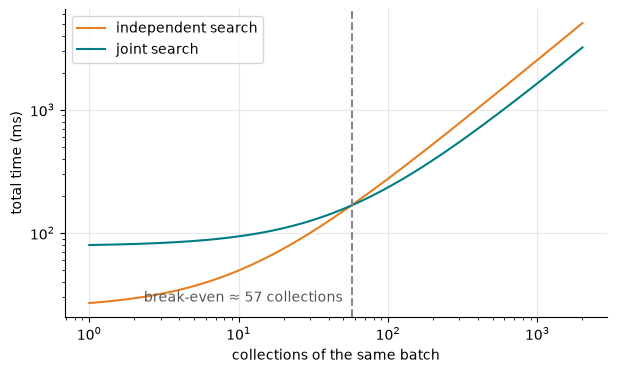

joint search costs 54 ms more to plan and saves 0.95 ms per collection, so it pays off after about 57 collections


In [5]:
extra = costs["joint"][0] - costs["independent"][0]
saving = costs["independent"][1] - costs["joint"][1]
breakeven = math.ceil(extra / saving) if saving > 0 else None

R = np.geomspace(1, max(2000, 4 * (breakeven or 0)), 200)
fig, ax = plt.subplots(figsize=(7, 4))
for search, color in (("independent", "#E67E22"), ("joint", "#007D84")):
    cold, warm = costs[search]
    ax.plot(R, cold + R * warm, color=color, label=f"{search} search")
ax.set_xscale("log")
ax.set_yscale("log")
if breakeven:
    ax.axvline(breakeven, color="#888888", linestyle="--")
    ax.text(breakeven / 1.15, 0.05, f"break-even ≈ {breakeven} collections", ha="right",
            transform=ax.get_xaxis_transform(), color="#555555")
ax.set_xlabel("collections of the same batch")
ax.set_ylabel("total time (ms)")
ax.legend()
tidy(ax)
plt.show()

if breakeven:
    print(f"joint search costs {extra:.0f} ms more to plan and saves {saving:.2f} ms per collection, "
          f"so it pays off after about {breakeven} collections")
else:
    print("joint search does not pay off here: it is not cheaper per collection")

For a one-off evaluation independent search wins easily, because planning dominates.
Joint search only pays off when the *identical* batch is collected many times. In a
variational algorithm the angles change at every step, so the cache never hits, which
brings us to the last scenario.

## 3. Changing parameters: replaying the structure (experimental)

In a variational loop the circuit keeps its shape while the angles change. The
expensive part of joint planning, deciding which questions to group and where to cut,
depends only on that shape. LazyQC can record those decisions as a *structural
template* and replay them for new angles, skipping the search.

> This uses an experimental, private hook (`plan_batch(..., _structural_hints=...)`),
> so its interface may change.

In [6]:
gammas = [Parameter(f"gamma_{k}") for k in range(len(star_edges))]
ansatz = qaoa(star_edges, gammas=gammas)  # angles left open
rng = random.Random(11)
steps = [ansatz.bind(**{g.name: rng.uniform(-1, 1) for g in gammas}) for _ in range(4)]


def questions(program):
    return [program.expectation({a: "Z", b: "Z"}) for a, b in star_edges]


options = dict(cutting=cut_options("joint"), strategy="auto", **memory)
template = plan_batch(questions(steps[0]), **options).explain()["search"]["structural_template"]

rows = []
for step, program in enumerate(steps[1:], start=1):
    requests = questions(program)
    fresh, fresh_ms = timed(lambda: plan_batch(requests, **options), repeats=3)
    replay, replay_ms = timed(lambda: plan_batch(requests, _structural_hints=template, **options), repeats=3)
    hit = replay.explain()["search"]["analysis"].get("structural_hit") == 1
    same = len(replay.selected.tasks) == len(fresh.selected.tasks) and replay.selected.score == fresh.selected.score
    dense = plan_all(requests, strategy="full").collect().values
    error = max(abs(v - d) for v, d in zip(replay.collect().values, dense))
    rows.append((step, fresh_ms, replay_ms, fresh_ms / replay_ms, hit, same, error))
table(rows, ["step", "fresh search (ms)", "replay (ms)", "speed-up", "template used", "same plan", "error vs dense"])

| step | fresh search (ms) | replay (ms) | speed-up | template used | same plan | error vs dense |
|---|---|---|---|---|---|---|
| 1 | 148 | 4.14 | 35.8 | yes | yes | 2.1e-16 |
| 2 | 84.4 | 4.60 | 18.4 | yes | yes | 3.3e-16 |
| 3 | 79.0 | 4.19 | 18.8 | yes | yes | 2.8e-16 |

Replay gives the same plan as a fresh search, in a fraction of the planning time, and
the answers still match the dense statevector. It only applies while the structure is
unchanged: if the circuit's shape changed, the template would be rejected and the
planner would search from scratch.

## Rules of thumb

| Situation | Good choice | Why |
|---|---|---|
| Small circuit, one batch | Direct statevector (Qulacs) | One cheap state answers everything; planning cannot repay itself |
| Many questions on separable or local parts | LazyQC grouped | Shared preparations on narrow cones keep states small |
| Parameter-shift gradients of a local circuit | LazyQC grouped | Shifts outside a cone share its task and give exact zeros (notebook 03) |
| Wider than memory, narrow cones | LazyQC | Only the cones are simulated (notebook 03) |
| Must cut, evaluated once | Independent cut search | Joint search costs more to plan than it saves |
| Must cut, same batch collected many times | Joint search with a `PlanningCache` | Fewer experiments per collection repay the search after the break-even above |
| Same circuit, new angles each step | Structural replay | Keeps the expensive decisions and rebinds the numbers |
| Cones span the whole register | Dense statevector | Nothing to remove, so the planner keeps the full plan anyway |
| Wider than memory, saturated cones | Tensor networks such as MPS | LazyQC refuses; a shared MPS can still work |
| Scalar-loss gradient at small widths | Adjoint differentiation | About two passes over one state |

The crossover points (qubit count, number of repeated collections, cone width) decide,
and they depend on the workload and the machine. That is why LazyQC explains its
choices instead of hiding them.